In [1]:
!pip install -q landingai-ade pillow pydantic

In [4]:
from landingai_ade import LandingAIADE
from getpass import getpass

API_KEY = getpass("Enter your Landing AI API Key: ")

client = LandingAIADE(apikey=API_KEY)

print("Landing AI client initialized successfully!")

Enter your Landing AI API Key: ··········
Landing AI client initialized successfully!


Saving Amoxicillin Capsule Bottle Product Photo.png to Amoxicillin Capsule Bottle Product Photo.png


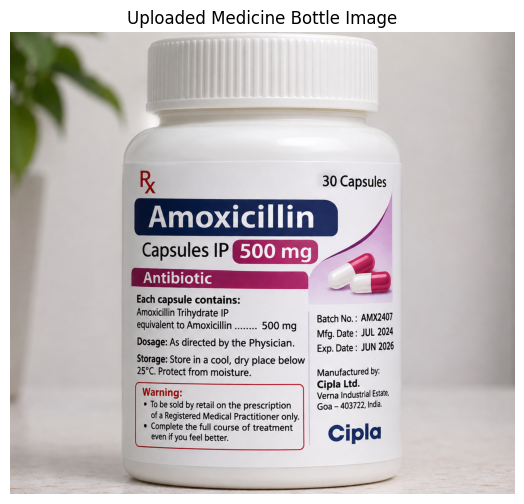

Image uploaded successfully!
Filename: Amoxicillin Capsule Bottle Product Photo.png


In [9]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
import io


uploaded = files.upload()


filename = next(iter(uploaded))

image = Image.open(io.BytesIO(uploaded[filename]))


plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Uploaded Medicine Bottle Image")
plt.show()

print("Image uploaded successfully!")
print("Filename:", filename)

In [10]:
from pathlib import Path


try:
    result = client.parse(
        document=Path(filename)
    )

    extracted_text = result.markdown

    print("MEDICINE BOTTLE LABEL - EXTRACTED TEXT")
    print("=" * 50)
    print(extracted_text)

except Exception as e:
    print("Error while reading medicine label:")
    print(type(e).__name__, str(e))

MEDICINE BOTTLE LABEL - EXTRACTED TEXT
<a id='12d26d1b-323f-44ef-ac64-498c0ab975e8'></a>

Rx
30 Capsules

# Amoxicillin

## Capsules IP 500 mg

### Antibiotic

Each capsule contains:

[Image: Two red and white capsules]

<a id='9dcc7a3e-e902-40bd-ac2f-90444f5371d6'></a>

**Each capsule contains:**
Amoxicillin Trihydrate IP
equivalent to Amoxicillin ... 500 mg

**Dosage:** As directed by the Physician.

**Storage:** Store in a cool, dry place below 25°C. Protect from moisture.

<a id='5b34967d-3fa6-4556-ac0f-113f658b25c6'></a>

### Warning:
* To be sold by retail on the prescription of a Registered Medical Practitioner only.
* Complete the full course of treatment even if you feel better.

<a id='6fa5754b-613c-4053-9e21-d6ec118f06da'></a>

Batch No. : AMX2407
Mfg. Date : JUL 2024
Exp. Date : JUN 2026

<a id='50c1d109-5c70-4fb6-a8e8-4addfaf9e0c4'></a>

Manufactured by:
Cipla Ltd.
Verna Industrial Estate,
Goa – 403722, India.

<a id='e061daab-e18b-4e2d-8cea-7d5b467e056d'></a>

Cipla


In [11]:
import re


cleaned_text = re.sub(r"<[^>]+>", "", extracted_text)


cleaned_text = re.sub(r"\n\s*\n+", "\n", cleaned_text)


cleaned_text = cleaned_text.strip()

print("CLEANED MEDICINE LABEL")
print("=" * 50)
print(cleaned_text)

CLEANED MEDICINE LABEL
Rx
30 Capsules
# Amoxicillin
## Capsules IP 500 mg
### Antibiotic
Each capsule contains:
[Image: Two red and white capsules]
**Each capsule contains:**
Amoxicillin Trihydrate IP
equivalent to Amoxicillin ... 500 mg
**Dosage:** As directed by the Physician.
**Storage:** Store in a cool, dry place below 25°C. Protect from moisture.
### Warning:
* To be sold by retail on the prescription of a Registered Medical Practitioner only.
* Complete the full course of treatment even if you feel better.
Batch No. : AMX2407
Mfg. Date : JUL 2024
Exp. Date : JUN 2026
Manufactured by:
Cipla Ltd.
Verna Industrial Estate,
Goa – 403722, India.
Cipla


In [12]:
import re
import json

def extract_medicine_details(text):
    details = {
        "Medicine Name": "Not found",
        "Medicine Type": "Not found",
        "Strength": "Not found",
        "Batch Number": "Not found",
        "Manufacturing Date": "Not found",
        "Expiry Date": "Not found",
        "Manufacturer": "Not found"
    }

    # Identify medicine type
    if re.search(r"hom[o]?eopathic", text, re.I):
        details["Medicine Type"] = "Homeopathic"
    elif re.search(r"ayurvedic", text, re.I):
        details["Medicine Type"] = "Ayurvedic"
    elif re.search(r"allopathic", text, re.I):
        details["Medicine Type"] = "Allopathic"

    # Medicine name (look for common label keywords)
    name_match = re.search(
        r"(?:Medicine Name|Product Name|Brand Name)\s*[:\-]\s*(.+)",
        text, re.I
    )
    if name_match:
        details["Medicine Name"] = name_match.group(1).strip()

    # Strength
    strength_match = re.search(
        r"\b\d+(?:\.\d+)?\s*(?:mg|mcg|g|ml|IU)\b",
        text, re.I
    )
    if strength_match:
        details["Strength"] = strength_match.group()

    # Batch number
    batch_match = re.search(
        r"(?:Batch No\.?|Batch Number|B\.?\s*No\.?)\s*[:\-]?\s*([A-Z0-9/-]+)",
        text, re.I
    )
    if batch_match:
        details["Batch Number"] = batch_match.group(1)

    # Manufacturing date
    mfg_match = re.search(
        r"(?:MFG|MFD|Manufacturing Date)\s*[:\-]?\s*(\d{1,2}[/-]\d{2,4})",
        text, re.I
    )
    if mfg_match:
        details["Manufacturing Date"] = mfg_match.group(1)

    # Expiry date
    exp_match = re.search(
        r"(?:EXP|Expiry|Expiry Date|Use Before)\s*[:\-]?\s*(\d{1,2}[/-]\d{2,4})",
        text, re.I
    )
    if exp_match:
        details["Expiry Date"] = exp_match.group(1)

    # Manufacturer
    manufacturer_match = re.search(
        r"(?:Manufactured by|Mfg\.? by)\s*[:\-]?\s*([^\n]+)",
        text, re.I
    )
    if manufacturer_match:
        details["Manufacturer"] = manufacturer_match.group(1).strip()

    return details


medicine_details = extract_medicine_details(cleaned_text)

print("STRUCTURED MEDICINE INFORMATION")
print("=" * 50)
print(json.dumps(medicine_details, indent=4))

STRUCTURED MEDICINE INFORMATION
{
    "Medicine Name": "Not found",
    "Medicine Type": "Not found",
    "Strength": "500 mg",
    "Batch Number": "AMX2407",
    "Manufacturing Date": "Not found",
    "Expiry Date": "Not found",
    "Manufacturer": "Cipla Ltd."
}


In [13]:
from pydantic import BaseModel, Field
from typing import Optional

# Define the information to extract
class MedicineLabel(BaseModel):
    medicine_name: Optional[str] = Field(
        default=None,
        description="Exact medicine or product name printed on the label"
    )

    medicine_type: Optional[str] = Field(
        default=None,
        description="Type of medicine explicitly stated on the label"
    )

    strength: Optional[str] = Field(
        default=None,
        description="Medicine strength or concentration with units"
    )

    batch_number: Optional[str] = Field(
        default=None,
        description="Batch or lot number"
    )

    manufacturing_date: Optional[str] = Field(
        default=None,
        description="Manufacturing date exactly as printed"
    )

    expiry_date: Optional[str] = Field(
        default=None,
        description="Expiry date exactly as printed"
    )

    manufacturer: Optional[str] = Field(
        default=None,
        description="Manufacturer name"
    )

    storage_instructions: Optional[str] = Field(
        default=None,
        description="Storage instructions printed on the label"
    )

    warnings: Optional[str] = Field(
        default=None,
        description="Warnings explicitly printed on the label"
    )


print("Medicine extraction schema created successfully!")
print(MedicineLabel.model_json_schema())

Medicine extraction schema created successfully!
{'properties': {'medicine_name': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None, 'description': 'Exact medicine or product name printed on the label', 'title': 'Medicine Name'}, 'medicine_type': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None, 'description': 'Type of medicine explicitly stated on the label', 'title': 'Medicine Type'}, 'strength': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None, 'description': 'Medicine strength or concentration with units', 'title': 'Strength'}, 'batch_number': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None, 'description': 'Batch or lot number', 'title': 'Batch Number'}, 'manufacturing_date': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None, 'description': 'Manufacturing date exactly as printed', 'title': 'Manufacturing Date'}, 'expiry_date': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None, 'descr

In [14]:
import json

try:
    extraction_result = client.v2.extract(
        markdown=extracted_text,
        schema=MedicineLabel.model_json_schema()
    )

    print("AI-EXTRACTED MEDICINE INFORMATION")
    print("=" * 50)
    print(extraction_result)

except Exception as e:
    print("Error:", type(e).__name__)
    print(str(e))

AI-EXTRACTED MEDICINE INFORMATION
V2ExtractResult(extraction={'batch_number': 'AMX2407', 'expiry_date': 'JUN 2026', 'manufacturer': 'Cipla Ltd.', 'manufacturing_date': 'JUL 2024', 'medicine_name': 'Amoxicillin', 'medicine_type': 'Capsules', 'storage_instructions': 'Store in a cool, dry place below 25°C. Protect from moisture.', 'strength': '500 mg', 'warnings': 'To be sold by retail on the prescription of a Registered Medical Practitioner only. Complete the full course of treatment even if you feel better.'}, extraction_metadata={'batch_number': {'ranges': [{'end': 729, 'start': 710}], 'value': 'AMX2407'}, 'expiry_date': {'ranges': [{'end': 771, 'start': 751}], 'value': 'JUN 2026'}, 'manufacturer': {'ranges': [{'end': 851, 'start': 841}], 'value': 'Cipla Ltd.'}, 'manufacturing_date': {'ranges': [{'end': 750, 'start': 730}], 'value': 'JUL 2024'}, 'medicine_name': {'ranges': [{'end': 80, 'start': 67}], 'value': 'Amoxicillin'}, 'medicine_type': {'ranges': [{'end': 65, 'start': 54}, {'end'

In [15]:
import pandas as pd
from IPython.display import display

# Get structured extraction dictionary
medicine_data = extraction_result.extraction

# Convert into readable table
report = pd.DataFrame({
    "Field": [
        key.replace("_", " ").title()
        for key in medicine_data.keys()
    ],
    "Extracted Information": [
        value if value is not None else "Not detected"
        for value in medicine_data.values()
    ]
})

print("MEDICINE LABEL COGNITIVE ASSISTANT")
print("=" * 50)

display(report)

print("\nAnalysis completed successfully!")

MEDICINE LABEL COGNITIVE ASSISTANT


,Field,Extracted Information
0,Batch Number,AMX2407
1,Expiry Date,JUN 2026
2,Manufacturer,Cipla Ltd.
3,Manufacturing Date,JUL 2024
4,Medicine Name,Amoxicillin
5,Medicine Type,Capsules
6,Storage Instructions,"Store in a cool, dry place below 25°C. Protect..."
7,Strength,500 mg
8,Warnings,To be sold by retail on the prescription of a ...



Analysis completed successfully!
